#Building a SimpleRNN Model for Weather Temperature Prediction

#Objective

The goal of this assignment is to design, implement, and evaluate a Recurrent Neural Network (RNN) model (using SimpleRNN) to forecast the next day’s temperature based on past weather data.


In [1]:
#Importing the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [3]:
# Loading and exploring the dataset
from google.colab import files
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv("/content/Madrid Daily Weather 1997-2015.csv")

print("Dataset shape:", df.shape)

display(df.head(10))

Saving Madrid Daily Weather 1997-2015.csv to Madrid Daily Weather 1997-2015 (1).csv
Dataset shape: (6812, 23)


,CET,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
0,1997-01-01,7.0,4.0,2.0,5.0,3.0,2.0,100.0,95.0,76.0,...,10.0,9.0,4.0,13,6,NaN,0.0,6.0,NaN,229
1,1997-01-02,7.0,3.0,0.0,6.0,3.0,0.0,100.0,92.0,71.0,...,10.0,9.0,4.0,26,8,47.0,0.0,5.0,Rain,143
2,1997-01-03,5.0,3.0,2.0,5.0,1.0,-1.0,100.0,85.0,70.0,...,10.0,10.0,7.0,27,19,NaN,0.0,6.0,Rain-Snow,256
3,1997-01-04,7.0,3.0,-1.0,-2.0,-3.0,-4.0,86.0,63.0,49.0,...,10.0,10.0,10.0,27,19,40.0,0.0,2.0,NaN,284
4,1997-01-05,2.0,0.0,-1.0,2.0,0.0,-3.0,100.0,95.0,86.0,...,10.0,5.0,1.0,14,6,NaN,0.0,7.0,Snow,2
5,1997-01-06,7.0,3.0,1.0,2.0,-1.0,-3.0,100.0,82.0,57.0,...,10.0,10.0,10.0,11,5,NaN,0.0,4.0,NaN,64
6,1997-01-07,2.0,0.0,-2.0,1.0,-1.0,-3.0,100.0,93.0,75.0,...,10.0,7.0,0.0,6,2,NaN,0.0,7.0,Snow,43
7,1997-01-08,8.0,4.0,1.0,7.0,4.0,1.0,100.0,96.0,87.0,...,10.0,8.0,4.0,26,8,NaN,0.0,7.0,Rain,273
8,1997-01-09,12.0,10.0,8.0,8.0,3.0,0.0,100.0,65.0,44.0,...,10.0,10.0,10.0,48,23,48.0,0.0,4.0,Rain,274
9,1997-01-10,13.0,8.0,3.0,8.0,5.0,1.0,93.0,83.0,63.0,...,10.0,10.0,10.0,13,5,NaN,0.0,5.0,NaN,100


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Column names:
['CET', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC', 'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity', ' Mean Humidity', ' Min Humidity', ' Max Sea Level PressurehPa', ' Mean Sea Level PressurehPa', ' Min Sea Level PressurehPa', ' Max VisibilityKm', ' Mean VisibilityKm', ' Min VisibilitykM', ' Max Wind SpeedKm/h', ' Mean Wind SpeedKm/h', ' Max Gust SpeedKm/h', 'Precipitationmm', ' CloudCover', ' Events', 'WindDirDegrees']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6812 entries, 0 to 6811
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CET                          6812 non-null   object 
 1   Max TemperatureC             6810 non-null   float64
 2   Mean TemperatureC            6809 non-null   float64
 3   Min TemperatureC             6810 non-null   float64
 4   Dew PointC                   6810 non-null   fl

,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,Max Sea Level PressurehPa,...,Min Sea Level PressurehPa,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,WindDirDegrees
count,6810.000000,6809.000000,6810.000000,6810.000000,6810.000000,6810.000000,6810.000000,6810.000000,6810.000000,6812.000000,...,6812.000000,5872.000000,5872.000000,5872.000000,6812.000000,6812.000000,3506.000000,6812.000000,5440.000000,6812.000000
mean,21.039648,14.658687,8.640529,8.120705,4.976211,1.451248,81.139354,57.971366,34.729369,1020.529360,...,1015.217410,14.644074,11.719857,9.134877,21.953171,9.170728,43.988306,0.111182,3.206066,197.234586
std,8.867187,7.580461,6.837626,4.741067,4.654270,4.909705,17.531839,19.675744,19.320359,6.235941,...,6.944745,8.770024,5.592324,5.075065,9.903914,5.110013,12.252462,0.967174,1.808948,119.872777
min,0.000000,-3.000000,-10.000000,-12.000000,-15.000000,-22.000000,16.000000,15.000000,4.000000,994.000000,...,965.000000,1.000000,0.000000,0.000000,0.000000,0.000000,19.000000,0.000000,0.000000,-1.000000
25%,13.000000,8.000000,3.000000,5.000000,2.000000,-2.000000,68.000000,41.000000,19.000000,1017.000000,...,1011.000000,10.000000,10.000000,7.000000,14.000000,6.000000,35.000000,0.000000,2.000000,66.000000
50%,20.000000,14.000000,9.000000,8.000000,6.000000,2.000000,87.000000,59.000000,32.000000,1020.000000,...,1015.000000,10.000000,10.000000,10.000000,21.000000,8.000000,42.000000,0.000000,3.000000,223.000000
75%,29.000000,21.000000,14.000000,12.000000,8.000000,5.000000,94.000000,74.000000,47.750000,1024.000000,...,1019.000000,10.000000,10.000000,10.000000,27.000000,11.000000,52.000000,0.000000,5.000000,299.000000
max,41.000000,32.000000,28.000000,20.000000,16.000000,14.000000,100.000000,100.000000,100.000000,1047.000000,...,1041.000000,31.000000,31.000000,31.000000,182.000000,39.000000,103.000000,32.000000,8.000000,360.000000


In [5]:
#Clean the data and plot temperature trends
# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Convert CET into datetime format
df["CET"] = pd.to_datetime(df["CET"], errors="coerce")

# Sort records by date
df = df.sort_values("CET").reset_index(drop=True)

# Select the columns required for our model
data = df[
    ["CET", "Mean TemperatureC",
     "Mean Humidity", "Mean Wind SpeedKm/h"]
].copy()

# Check for missing values
print("Missing values before cleaning:")
print(data.isnull().sum())

# Remove rows with missing dates
data = data.dropna(subset=["CET"])

# Convert selected weather features to numeric values
features = [
    "Mean TemperatureC",
    "Mean Humidity",
    "Mean Wind SpeedKm/h"
]

for col in features:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Fill missing numerical values using time interpolation
data = data.set_index("CET")
data[features] = data[features].interpolate(method="time")

# Handle any remaining missing values at the beginning or end
data[features] = data[features].ffill().bfill()

# Return date to a regular column
data = data.reset_index()

print("\nDataset after cleaning:")
print(data.shape)
print(data.isnull().sum())

display(data.head(10))

Missing values before cleaning:
CET                    0
Mean TemperatureC      3
Mean Humidity          2
Mean Wind SpeedKm/h    0
dtype: int64

Dataset after cleaning:
(6812, 4)
CET                    0
Mean TemperatureC      0
Mean Humidity          0
Mean Wind SpeedKm/h    0
dtype: int64


,CET,Mean TemperatureC,Mean Humidity,Mean Wind SpeedKm/h
0,1997-01-01,4.0,95.0,6
1,1997-01-02,3.0,92.0,8
2,1997-01-03,3.0,85.0,19
3,1997-01-04,3.0,63.0,19
4,1997-01-05,0.0,95.0,6
5,1997-01-06,3.0,82.0,5
6,1997-01-07,0.0,93.0,2
7,1997-01-08,4.0,96.0,8
8,1997-01-09,10.0,65.0,23
9,1997-01-10,8.0,83.0,5


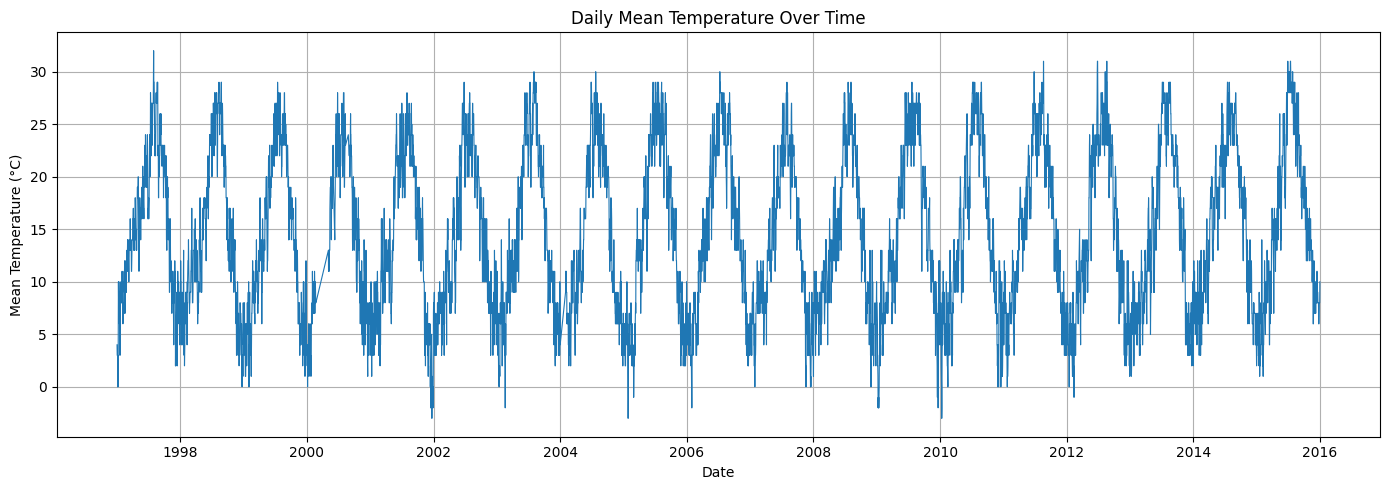

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    data["CET"],
    data["Mean TemperatureC"],
    linewidth=0.8
)

plt.title("Daily Mean Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Split the data and normalize it
sequence_length = 14

X_raw = data[features].values
y_raw = data["Mean TemperatureC"].values

n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Initialize separate scalers for inputs and target
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

# Fit scalers using training data only
feature_scaler.fit(X_raw[:train_end])
target_scaler.fit(y_raw[:train_end].reshape(-1, 1))

# Transform all observations using the training-fitted scalers
X_scaled = feature_scaler.transform(X_raw)
y_scaled = target_scaler.transform(
    y_raw.reshape(-1, 1)
).flatten()

print("Training rows:", train_end)
print("Validation rows:", val_end - train_end)
print("Test rows:", n - val_end)
print("Input features:", features)
print("Sequence length:", sequence_length)

Training rows: 4768
Validation rows: 1022
Test rows: 1022
Input features: ['Mean TemperatureC', 'Mean Humidity', 'Mean Wind SpeedKm/h']
Sequence length: 14


In [8]:
#Create the input sequences
X_sequences = []
y_sequences = []
target_indices = []

for i in range(sequence_length, n):
    X_sequences.append(X_scaled[i-sequence_length:i])
    y_sequences.append(y_scaled[i])
    target_indices.append(i)

X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)
target_indices = np.array(target_indices)

# Split based on the date of the target observation
train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train = X_sequences[train_mask]
y_train = y_sequences[train_mask]

X_val = X_sequences[val_mask]
y_val = y_sequences[val_mask]

X_test = X_sequences[test_mask]
y_test = y_sequences[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (4754, 14, 3)
y_train shape: (4754,)
X_val shape: (1022, 14, 3)
X_test shape: (1022, 14, 3)


In [9]:
# Build the SimpleRNN model
model = Sequential([
    SimpleRNN(
        32,
        activation="tanh",
        input_shape=(sequence_length, len(features))
    ),
    Dropout(0.2),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

SimpleRNN(32): learns patterns from the previous 14 days.



Dropout(0.2): randomly disables 20% of units during training to help reduce overfitting.



Dense(1): outputs one predicted temperature.



Adam: optimizer that adjusts the model's weights.



MSE: loss function that penalizes prediction errors.



MAE: tracks the average absolute error in scaled units during training.

In [10]:
# Train the model
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0636 - mae: 0.1872 - val_loss: 0.0125 - val_mae: 0.0860
Epoch 2/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0190 - mae: 0.1089 - val_loss: 0.0073 - val_mae: 0.0655
Epoch 3/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0126 - mae: 0.0888 - val_loss: 0.0051 - val_mae: 0.0559
Epoch 4/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0104 - mae: 0.0804 - val_loss: 0.0043 - val_mae: 0.0515
Epoch 5/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0089 - mae: 0.0750 - val_loss: 0.0040 - val_mae: 0.0498
Epoch 6/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0078 - mae: 0.0697 - val_loss: 0.0036 - val_mae: 0.0477
Epoch 7/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0072 - mae: 0.0672 - val_loss: 0.0034 - val_mae: 0.0464
Epoch 8/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0066 - mae: 0.0644 - val_loss: 0.0035 - val_mae: 0.0462
Epoch 9/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/

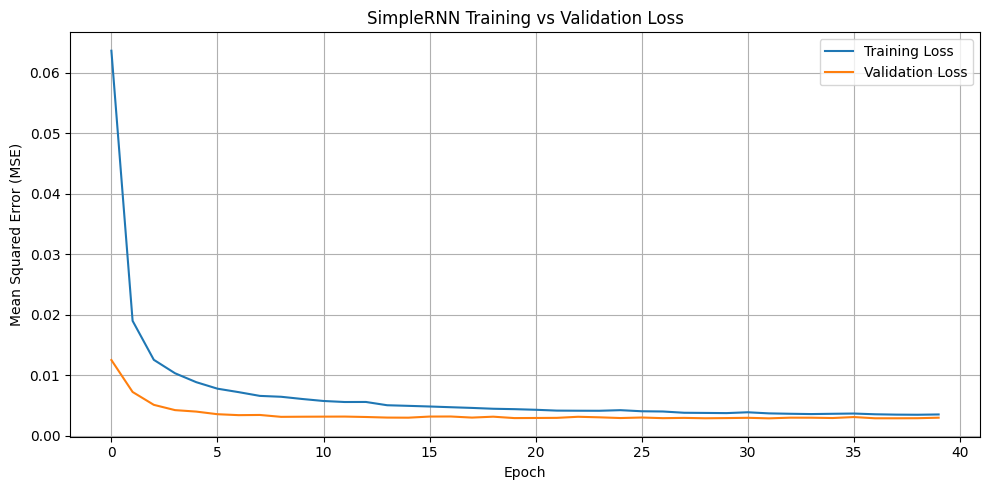

In [11]:
#Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("SimpleRNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# Evaluate the model on the test set
# Predict scaled temperatures
y_pred_scaled = model.predict(X_test)

# Convert predictions and actual values back to Celsius
y_pred = target_scaler.inverse_transform(
    y_pred_scaled
).flatten()

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# Calculate evaluation metrics
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

print(f"Test RMSE: {rmse:.3f} °C")
print(f"Test MAE:  {mae:.3f} °C")
print(f"Test R²:   {r2:.3f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Test RMSE: 1.834 °C
Test MAE:  1.413 °C
Test R²:   0.940


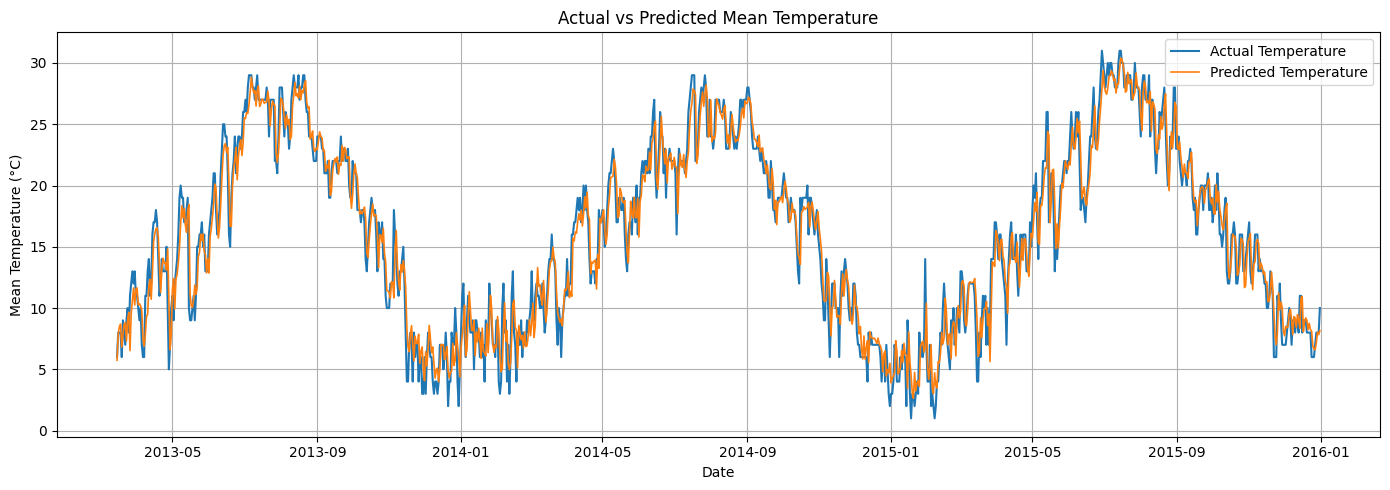

In [13]:
#Plot actual vs predicted temperatures
test_dates = data["CET"].iloc[target_indices[test_mask]]

plt.figure(figsize=(14, 5))

plt.plot(
    test_dates,
    y_actual,
    label="Actual Temperature",
    linewidth=1.5
)

plt.plot(
    test_dates,
    y_pred,
    label="Predicted Temperature",
    linewidth=1.2
)

plt.title("Actual vs Predicted Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# Forecast the next 7 days
# Get the most recent 14 days of scaled weather data
last_sequence = X_scaled[-sequence_length:].copy()

future_predictions = []

# Hold humidity and wind speed at their latest observed values
last_humidity = X_scaled[-1, 1]
last_wind_speed = X_scaled[-1, 2]

for day in range(7):

    # Reshape input for the RNN
    input_sequence = last_sequence.reshape(
        1, sequence_length, len(features)
    )

    # Predict the next day's scaled temperature
    next_temp_scaled = model.predict(
        input_sequence, verbose=0
    )[0, 0]

    future_predictions.append(next_temp_scaled)

    # Create the next day's input row
    next_row = np.array([
        next_temp_scaled,
        last_humidity,
        last_wind_speed
    ])

    # Move the sequence forward by one day
    last_sequence = np.vstack([
        last_sequence[1:],
        next_row
    ])

# Convert forecasts back to Celsius
future_temperatures = target_scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
).flatten()

# Generate forecast dates
last_date = data["CET"].iloc[-1]

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Mean Temperature (°C)": np.round(
        future_temperatures, 2
    )
})

display(forecast_df)

,Date,Predicted Mean Temperature (°C)
0,2016-01-01,9.49
1,2016-01-02,9.10
2,2016-01-03,9.01
3,2016-01-04,8.70
4,2016-01-05,8.60
5,2016-01-06,8.53
6,2016-01-07,8.31


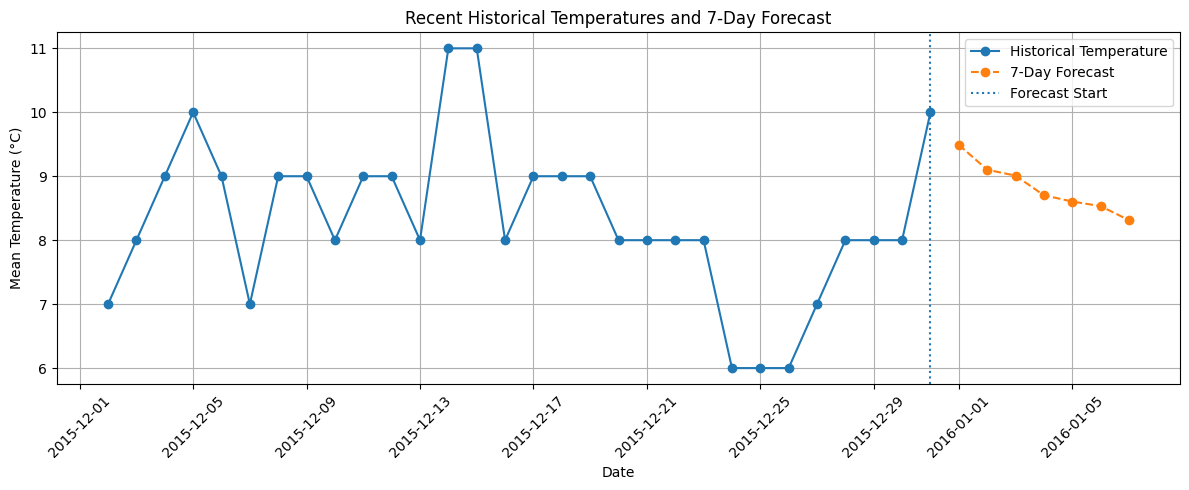

In [15]:
#Visualize historical temperatures and the 7-day forecast
# Plot the last 30 days of observed temperatures
recent_data = data.tail(30)

plt.figure(figsize=(12, 5))

plt.plot(
    recent_data["CET"],
    recent_data["Mean TemperatureC"],
    marker="o",
    label="Historical Temperature"
)

plt.plot(
    future_dates,
    future_temperatures,
    marker="o",
    linestyle="--",
    label="7-Day Forecast"
)

plt.axvline(
    last_date,
    linestyle=":",
    label="Forecast Start"
)

plt.title("Recent Historical Temperatures and 7-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Conclusion

A Simple Recurrent Neural Network (SimpleRNN) was developed using TensorFlow/Keras to predict the next day's mean temperature from the previous 14 days of weather observations. The input features included mean temperature, mean humidity, and mean wind speed.

The dataset was cleaned, missing numerical values were handled using time-based interpolation, and the features were normalized using MinMaxScaler. The data was divided chronologically into training, validation, and testing sets to preserve the time-series order.

The model was trained using the Adam optimizer and Mean Squared Error loss, with Mean Absolute Error monitored as an additional metric. Dropout and early stopping were used to help reduce overfitting.

On the test set, the model achieved an RMSE of 1.834°C, an MAE of 1.413°C, and an R² score of 0.940. These results indicate that the model performed well on the held-out test data.

Finally, a recursive seven-day forecast was generated using the trained model. Since future humidity and wind speed observations were unavailable, their most recent scaled values were held constant during forecasting. Therefore, the seven-day predictions demonstrate the forecasting process but should not be interpreted as an operational weather forecast.